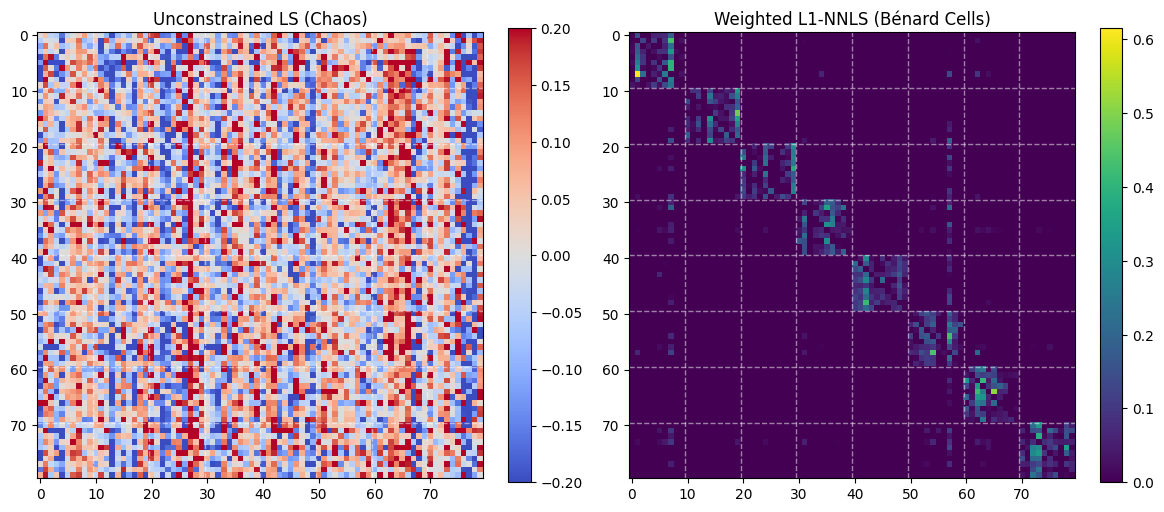


=== EQUITIES RESULTS ===
LS negative: 46.2%
NNLS negative: 0.0%
Intra-sector NNLS: 11.6%
Intra-sector Weighted: 83.1%


In [1]:
# ==========================================
# Analysis of S&P 500 Equities
# ==========================================
!pip install yfinance -q

import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.optimize import nnls, minimize

sectors = {
    'Tech': ['AAPL', 'MSFT', 'NVDA', 'AVGO', 'AMD', 'INTC', 'CSCO', 'ADBE', 'CRM', 'ORCL'],
    'Health': ['JNJ', 'UNH', 'PFE', 'MRK', 'ABBV', 'LLY', 'TMO', 'ABT', 'DHR', 'BMY'],
    'Finance': ['JPM', 'BAC', 'WFC', 'C', 'GS', 'MS', 'BLK', 'SCHW', 'AXP', 'USB'],
    'Consumer': ['AMZN', 'TSLA', 'HD', 'MCD', 'NKE', 'SBUX', 'TGT', 'LOW', 'BKNG', 'MAR'],
    'Energy': ['XOM', 'CVX', 'COP', 'SLB', 'EOG', 'HAL', 'MPC', 'PSX', 'VLO', 'OXY'],
    'Industrials': ['CAT', 'GE', 'HON', 'UPS', 'BA', 'LMT', 'RTX', 'DE', 'MMM', 'FDX'],
    'Utilities': ['NEE', 'DUK', 'SO', 'D', 'AEP', 'SRE', 'EXC', 'XEL', 'ED', 'PEG'],
    'Materials': ['LIN', 'APD', 'SHW', 'FCX', 'NEM', 'DOW', 'DD', 'NUE', 'VMC', 'MLM']
}
tickers = [t for sublist in sectors.values() for t in sublist]

print(f"Downloading data for {len(tickers)} stocks...")
raw_data = yf.download(tickers, start="2023-01-01", end="2024-01-01", progress=False, auto_adjust=True)
data = raw_data['Close'] if isinstance(raw_data.columns, pd.MultiIndex) else raw_data
data = data.ffill().bfill().dropna()
returns = data.pct_change().dropna()

X = returns.values
X = X - X.min(axis=0) + 1e-6
X_lag = X[:-1, :]
Y_cur = X[1:, :]
n_assets = X.shape[1]

sector_labels = []
for i, (sec_name, tks) in enumerate(sectors.items()):
    sector_labels.extend([i] * len(tks))
sector_labels = np.array(sector_labels)
dist_matrix = (sector_labels[:, None] != sector_labels[None, :]).astype(float)

W_nnls = np.zeros((n_assets, n_assets))
W_ls = np.zeros((n_assets, n_assets))

for i in range(n_assets):
    X_pred = X_lag.copy()
    X_pred[:, i] = 0.0
    w_i, _ = nnls(X_pred, Y_cur[:, i])
    W_nnls[i, :] = w_i
    w_ls, *_ = np.linalg.lstsq(X_pred, Y_cur[:, i], rcond=None)
    W_ls[i, :] = w_ls

scale_X, scale_Y = X_lag.max(), Y_cur.max()
X_lag_norm, Y_cur_norm = X_lag / scale_X, Y_cur / scale_Y
lambda_reg = 0.5
W_weighted = np.zeros((n_assets, n_assets))

for i in range(n_assets):
    X_pred = X_lag_norm.copy()
    X_pred[:, i] = 0.0
    y = Y_cur_norm[:, i]
    d = dist_matrix[i, :]
    def obj(w): return np.sum((X_pred @ w - y)**2) + lambda_reg * np.sum(d * w)
    def grad(w): return 2 * X_pred.T @ (X_pred @ w - y) + lambda_reg * d
    res = minimize(obj, np.zeros(n_assets), method='L-BFGS-B', jac=grad, bounds=[(0, None)]*n_assets)
    W_weighted[i, :] = res.x
W_weighted = W_weighted * (scale_Y / scale_X)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
im0 = axes[0].imshow(W_ls, cmap='coolwarm', vmin=-0.2, vmax=0.2)
axes[0].set_title('Unconstrained LS (Chaos)')
plt.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(W_weighted, cmap='viridis')
axes[1].set_title('Weighted L1-NNLS (Bénard Cells)')
for ax in axes:
    for i in range(1, 8):
        ax.axhline(i * 10 - 0.5, color='white', linestyle='--', linewidth=1, alpha=0.5)
        ax.axvline(i * 10 - 0.5, color='white', linestyle='--', linewidth=1, alpha=0.5)
plt.colorbar(im1, ax=axes[1], fraction=0.046)
plt.show()

print("\n=== EQUITIES RESULTS ===")
print(f"LS negative: {(W_ls < 0).mean() * 100:.1f}%")
print(f"NNLS negative: {(W_nnls < 0).mean() * 100:.1f}%")

thr = 0.01
mask_base = W_nnls > thr
mask_weighted = W_weighted > thr
np.fill_diagonal(mask_base, False)
np.fill_diagonal(mask_weighted, False)

same_sec_base = np.sum((dist_matrix == 0) & mask_base) / (np.sum(mask_base) + 1e-9)
same_sec_weighted = np.sum((dist_matrix == 0) & mask_weighted) / (np.sum(mask_weighted) + 1e-9)
print(f"Intra-sector NNLS: {same_sec_base * 100:.1f}%")
print(f"Intra-sector Weighted: {same_sec_weighted * 100:.1f}%")